# Autoencodeurs pour la détection d'anomalie et le clustering: Diagnostic de roulements de rame à grande vitesse à partir de signaux vibratoires
### 

**Objectif.** À partir des acquisitions du banc expérimental (5 états du roulement, 3 vitesses, 2 accéléromètres), on veut :
1. **détecter** automatiquement un roulement défectueux (détection d'anomalie) ;
2. **regrouper** les acquisitions selon leur état, sans utiliser les étiquettes (clustering).

**Plan du notebook**

| Partie | Contenu |
|---|---|
| 0 | Paramètres et imports |
| 1 | Inventaire des fichiers et séparation train / validation / test |
| 2 | EDA des signaux bruts |
| 3 | Construction de la base de données v1 (une ligne = un signal) |
| 4 | EDA de la base de données |
| 5 | Les autoencodeurs : principe |
| 6 | Détection d'anomalie |
| 7 | Clustering |
| 8 | Sauvegarde des modèles, bilan et pistes d'amélioration |

> Principe retenu : **un signal (= un fichier Excel = 1 seconde d'acquisition) = un exemple**. On ne découpe pas les signaux.

---
## 0. Paramètres et imports

Seule la variable `DATA_DIR` est à modifier : c'est le dossier qui contient `SAFE/`, `BALL/`, `INNER_RACE/`, `OUTER_RACE/`, `COMBINED/`.

In [1]:
import zipfile
from pathlib import Path
from xml.etree.ElementTree import iterparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns
from scipy import signal, stats
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             silhouette_score, adjusted_rand_score, normalized_mutual_info_score)

DATA_DIR = Path(r"Ecole Centrale Casablanca\Meryem ABTANE - PFE - Diagnostic des Défauts de Roulements")   # <-- À MODIFIER
FS = 25_600                                 # fréquence d'échantillonnage (Hz) : 25 600 points = 1 s
CANAUX = ["acceleration_vertbleu", "acceleration_vert"]
CLASSES = ["SAFE", "BALL", "INNER_RACE", "OUTER_RACE", "COMBINED"]
COULEURS = {"SAFE": "#2a7ab0", "BALL": "#d1495b", "INNER_RACE": "#e08a2c",
            "OUTER_RACE": "#3b9a5a", "COMBINED": "#7d5ba6"}
SEED = 42                                   # graine aléatoire -> résultats reproductibles
np.random.seed(SEED)

---
## 1. Inventaire des fichiers et séparation train / validation / test

### 1.1 Inventaire
On parcourt l'arborescence `CLASSE/classe_vitesse/fichier.xlsx` et on construit une table `meta` avec une ligne par fichier. La classe se lit dans le nom du dossier parent, la vitesse dans le suffixe du sous-dossier (`ball_15` → 15).

In [2]:
lignes = []
for f in sorted(DATA_DIR.glob("*/*/*.xlsx")):
    if f.name.startswith("~$"):            # fichiers temporaires créés par Excel
        continue
    lignes.append({"classe": f.parent.parent.name,
                   "vitesse": int(f.parent.name.split("_")[-1]),
                   "fichier": f.name,
                   "chemin": str(f)})
meta = pd.DataFrame(lignes)

print(f"{len(meta)} fichiers")
pd.crosstab(meta.classe, meta.vitesse, margins=True)

8432 fichiers


vitesse,10,15,20,All
classe,,,,
BALL,566,576,555,1697
COMBINED,550,575,519,1644
INNER_RACE,556,658,562,1776
OUTER_RACE,528,562,515,1605
SAFE,523,664,523,1710
All,2723,3035,2674,8432


### 1.2 Séparation train / validation / test — **avant tout prétraitement**

Pourquoi maintenant ? Toute opération qui « apprend » quelque chose des données (moyenne et écart-type de la standardisation, choix d'un seuil, entraînement...) ne doit voir **que** le jeu d'entraînement. Si le jeu de test influence ces choix, même indirectement, les performances mesurées sont trop optimistes : c'est une **fuite de données**.

- **train (70 %)** : apprendre les modèles et les normalisations ;
- **validation (15 %)** : régler les choix (seuil de détection, taille du modèle...) ;
- **test (15 %)** : mesurer les performances finales, une seule fois, à la fin.

Le découpage est **stratifié** par (classe, vitesse) : chaque ensemble contient les mêmes proportions de chaque condition expérimentale.

In [3]:
strate = meta.classe + "_" + meta.vitesse.astype(str)

idx_train, idx_reste = train_test_split(meta.index, test_size=0.30, stratify=strate, random_state=SEED)
idx_val, idx_test = train_test_split(idx_reste, test_size=0.50, stratify=strate[idx_reste], random_state=SEED)

meta["split"] = "train"
meta.loc[idx_val, "split"] = "val"
meta.loc[idx_test, "split"] = "test"

pd.crosstab(meta.classe, meta.split)[["train", "val", "test"]]

split,train,val,test
classe,,,
BALL,1188,254,255
COMBINED,1150,247,247
INNER_RACE,1243,267,266
OUTER_RACE,1124,240,241
SAFE,1197,257,256


---
## 2. EDA des signaux bruts

### 2.1 Lire un fichier
Les fichiers exportés par le logiciel National Instruments font planter `pd.read_excel` (feuille de styles non standard). Un `.xlsx` est en réalité une **archive ZIP contenant des fichiers XML** : on lit donc directement les valeurs dans le XML.

Vous n'avez pas besoin de comprendre le détail de cette fonction : retenez qu'elle renvoie un tableau numpy de forme `(25600, 2)` (25 600 instants × 2 capteurs).

In [10]:
NS = "{http://schemas.openxmlformats.org/spreadsheetml/2006/main}"

import unicodedata
N_POINTS = 25_600

def normaliser(nom):
    # " Accélération_Vert " -> "acceleration_vert" : sans espaces autour, minuscules, sans accents
    nom = unicodedata.normalize("NFKD", str(nom).strip().lower())
    return "".join(ch for ch in nom if not unicodedata.combining(ch))

def lire_signal(chemin):
    archive = zipfile.ZipFile(chemin)
    textes = []
    if "xl/sharedStrings.xml" in archive.namelist():
        for _, el in iterparse(archive.open("xl/sharedStrings.xml")):
            if el.tag == NS + "si":
                textes.append("".join(t.text or "" for t in el.iter(NS + "t")))
    lignes = []
    for _, el in iterparse(archive.open("xl/worksheets/sheet1.xml")):
        if el.tag == NS + "row":
            ligne = []
            for c in el.findall(NS + "c"):
                v = c.find(NS + "v")
                if c.get("t") == "s":
                    ligne.append(textes[int(v.text)])
                elif c.get("t") == "inlineStr":
                    ligne.append("".join(x.text or "" for x in c.iter(NS + "t")))
                else:
                    ligne.append(float(v.text) if v is not None else np.nan)
            lignes.append(ligne)
            el.clear()

    noms = [normaliser(n) for n in lignes[0]]
    df = pd.DataFrame(lignes[1:], columns=noms)

    manquants = [c for c in CANAUX if c not in df.columns]
    if manquants:
        raise ValueError(f"capteurs {manquants} absents ; colonnes du fichier : {lignes[0]}")
    if len(df) != N_POINTS:
        raise ValueError(f"{len(df)} points au lieu de {N_POINTS}")
    return df[CANAUX].to_numpy(dtype=np.float32)

In [11]:
def lire_entete(chemin):
    archive = zipfile.ZipFile(chemin)
    textes = []
    if "xl/sharedStrings.xml" in archive.namelist():
        for _, el in iterparse(archive.open("xl/sharedStrings.xml")):
            if el.tag == NS + "si":
                textes.append("".join(t.text or "" for t in el.iter(NS + "t")))
    for _, el in iterparse(archive.open("xl/worksheets/sheet1.xml")):
        if el.tag == NS + "row":                      # on s'arrête à la 1re ligne
            entete = []
            for c in el.findall(NS + "c"):
                v = c.find(NS + "v")
                if c.get("t") == "s":
                    entete.append(textes[int(v.text)])
                elif c.get("t") == "inlineStr":
                    entete.append("".join(x.text or "" for x in c.iter(NS + "t")))
                else:
                    entete.append("<nombre>")         # pas d'en-tête : la 1re ligne contient déjà des données
            return " | ".join(entete)                 # texte, et non plus tuple
    return "<feuille vide>"

meta["entete"] = Parallel(n_jobs=-1)(delayed(lire_entete)(c) for c in meta.chemin)
pd.crosstab(meta.entete, meta.classe)

classe,BALL,COMBINED,INNER_RACE,OUTER_RACE,SAFE
entete,,,,,
Pression acoustique | acceleration_vertbleu | acceleration_vert,0,18,0,0,0
Time | Accélération_hori_blue | Accélération_vert | Accélération_vertbleu | Pression acoustique,0,0,6,0,0
Time | acceleration_vertbleu | acceleration_vert,0,0,0,1,0
Time | acceleration_vertbleu | acceleration_vert,0,0,0,1603,1710
acceleration_vertbleu | acceleration_vert,1697,1626,1770,1,0


### 2.2 Un signal par classe

On compare un fichier **du jeu d'entraînement** par classe, **à la même vitesse** (sinon on verrait l'effet de la vitesse et non celui du défaut).

**Ce qu'il faut regarder :**
- **signal temporel** : un roulement défectueux produit des **chocs** (pics brefs) à chaque passage d'un élément sur le défaut ;
- **densité spectrale de puissance (DSP)** : comment l'énergie se répartit entre les fréquences. On utilise la méthode de **Welch** : le signal est découpé *en interne* en segments dont on moyenne les spectres (résultat moins bruité). Fréquence max visible : $f_s/2 = 12{,}8$ kHz (Nyquist).

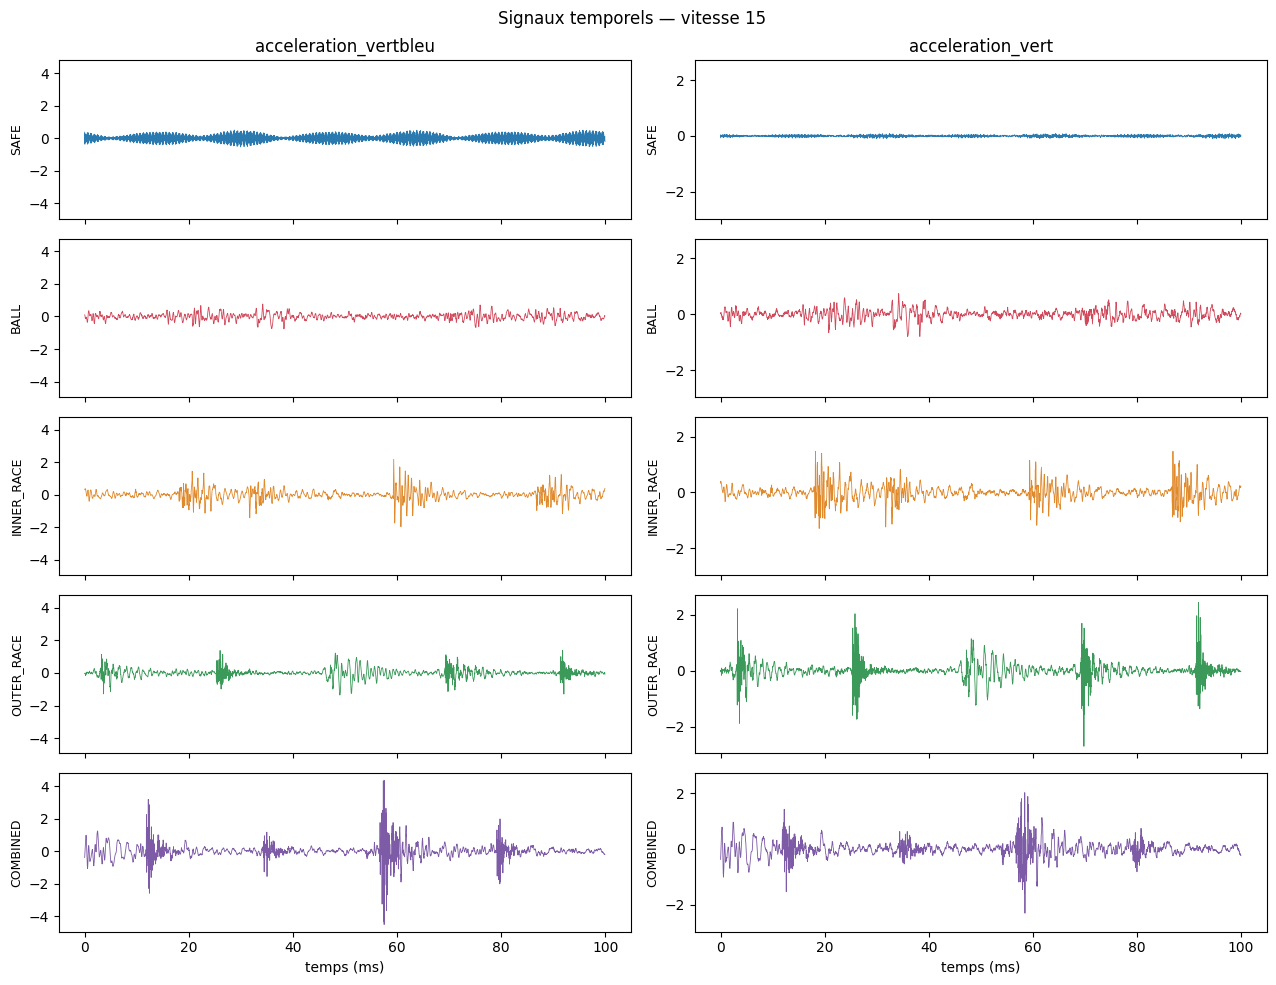

In [12]:
VITESSE = 15
exemples = {}
for c in CLASSES:
    choix = meta[(meta.split == "train") & (meta.classe == c) & (meta.vitesse == VITESSE)]
    exemples[c] = lire_signal(choix.chemin.iloc[0])

t_ms = np.arange(2560) / FS * 1000                    # 100 premières millisecondes
fig, ax = plt.subplots(len(CLASSES), 2, figsize=(13, 10), sharex=True, sharey="col")
for i, c in enumerate(CLASSES):
    for j, canal in enumerate(CANAUX):
        s = exemples[c][:2560, j]
        ax[i, j].plot(t_ms, s - s.mean(), lw=0.6, color=COULEURS[c])
        ax[i, j].set_ylabel(c, fontsize=9)
for j, canal in enumerate(CANAUX):
    ax[0, j].set_title(canal)
    ax[-1, j].set_xlabel("temps (ms)")
fig.suptitle(f"Signaux temporels — vitesse {VITESSE}")
plt.tight_layout(); plt.show()

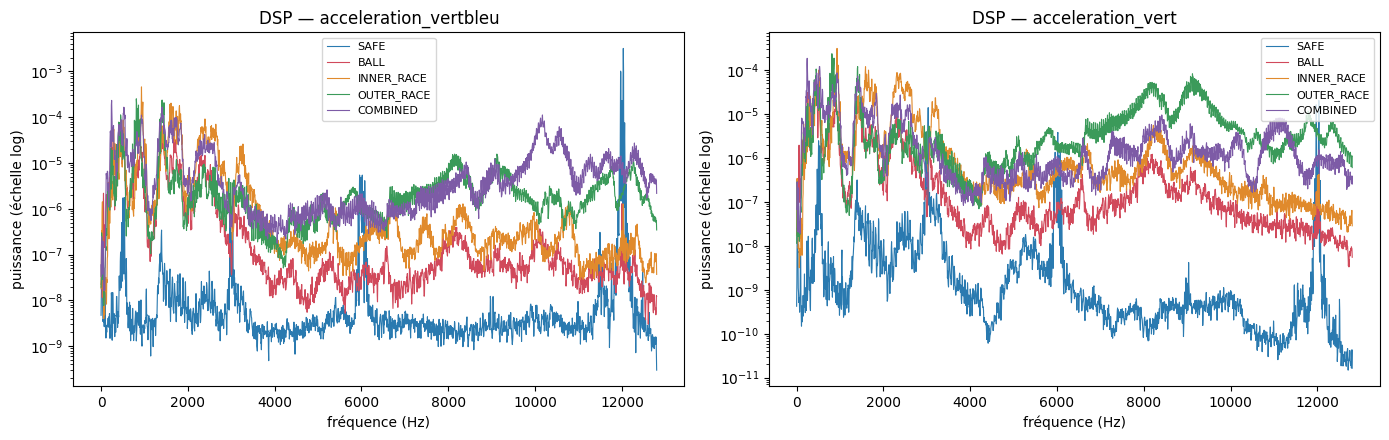

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for j, canal in enumerate(CANAUX):
    for c in CLASSES:
        s = exemples[c][:, j]
        f, P = signal.welch(s - s.mean(), fs=FS, nperseg=4096)
        ax[j].semilogy(f, P, lw=0.8, color=COULEURS[c], label=c)
    ax[j].set(title=f"DSP — {canal}", xlabel="fréquence (Hz)", ylabel="puissance (échelle log)")
    ax[j].legend(fontsize=8)
plt.tight_layout(); plt.show()

> **À noter dans le rapport :** observez si certaines raies (par ex. vers 3, 6 ou 12 kHz) n'apparaissent que dans une classe. Si elles viennent des conditions d'acquisition (session, câblage, alimentation) plutôt que du roulement, un modèle risque d'apprendre à reconnaître *la session* au lieu du *défaut*.

---
## 3. Construction de la base de données v1

Un autoencodeur « classique » (dense) prend en entrée un **vecteur de taille fixe**. On résume donc chaque signal de 25 600 × 2 points par un vecteur de **descripteurs** (*features*) : la base devient un tableau avec **une ligne par signal**.

### 3.1 Les descripteurs (calculés pour chacun des 2 capteurs)

**Descripteurs temporels** (après avoir retiré la moyenne du signal) :

| Descripteur | Formule | Interprétation |
|---|---|---|
| RMS | $\sqrt{\frac{1}{N}\sum x_i^2}$ | énergie vibratoire globale |
| Kurtosis | $\frac{\frac{1}{N}\sum x_i^4}{\text{RMS}^4}$ | ≈ 3 pour un bruit gaussien, **> 3 en présence de chocs** |
| Facteur de crête | $\frac{\max\lvert x\rvert}{\text{RMS}}$ | importance des pics par rapport au niveau moyen |
| Skewness | $\frac{\frac{1}{N}\sum x_i^3}{\text{RMS}^3}$ | asymétrie du signal |
| Crête-à-crête | $\max x - \min x$ | amplitude totale |

**Descripteurs fréquentiels** : on découpe le spectre (0 – 12,8 kHz) en **8 bandes de 1,6 kHz** et on calcule l'énergie de chaque bande (en log, car les énergies varient sur plusieurs ordres de grandeur). Ils indiquent **où** se situe l'énergie, ce qui aide à distinguer les types de défauts.

→ 5 + 8 = 13 descripteurs par capteur, soit **26 colonnes**.

On garde aussi le **spectre complet** (log-DSP, 256 fréquences par capteur) : il servira de 2ᵉ représentation, plus riche, en partie 6.5.

In [14]:
SUFFIXE = {"acceleration_vertbleu": "vb", "acceleration_vert": "v"}
N_BANDES = 8

def extraire(chemin):
    sig = lire_signal(chemin)
    desc, spectre = {}, []
    for j, canal in enumerate(CANAUX):
        x = sig[:, j] - sig[:, j].mean()
        rms = np.sqrt(np.mean(x ** 2))
        s = SUFFIXE[canal]
        desc[f"rms_{s}"] = rms
        desc[f"kurtosis_{s}"] = stats.kurtosis(x, fisher=False)
        desc[f"crete_{s}"] = np.max(np.abs(x)) / rms
        desc[f"skew_{s}"] = stats.skew(x)
        desc[f"pkpk_{s}"] = x.max() - x.min()

        f, P = signal.welch(x, fs=FS, nperseg=512)      # 257 fréquences de 0 à 12,8 kHz
        for b, bande in enumerate(np.array_split(P[1:], N_BANDES)):
            desc[f"bande{b + 1}_{s}"] = np.log10(bande.sum())
        spectre.append(np.log10(P[1:]))                 # 256 valeurs
    return desc, np.concatenate(spectre)

desc, spec = extraire(meta.chemin[0])
print(len(desc), "descripteurs ;", spec.shape, "points de spectre")
desc

26 descripteurs ; (512,) points de spectre


{'rms_vb': np.float32(0.08056367),
 'kurtosis_vb': np.float32(6.4983706),
 'crete_vb': np.float32(6.3328304),
 'skew_vb': np.float32(0.024661431),
 'pkpk_vb': np.float32(1.012888),
 'bande1_vb': np.float32(-3.9840472),
 'bande2_vb': np.float32(-4.6207395),
 'bande3_vb': np.float32(-6.4422736),
 'bande4_vb': np.float32(-6.501702),
 'bande5_vb': np.float32(-6.4713345),
 'bande6_vb': np.float32(-6.3046455),
 'bande7_vb': np.float32(-6.278006),
 'bande8_vb': np.float32(-6.258279),
 'rms_v': np.float32(0.069034755),
 'kurtosis_v': np.float32(6.7906327),
 'crete_v': np.float32(6.777604),
 'skew_v': np.float32(-0.03589496),
 'pkpk_v': np.float32(0.921191),
 'bande1_v': np.float32(-4.0899734),
 'bande2_v': np.float32(-5.0040126),
 'bande3_v': np.float32(-6.562283),
 'bande4_v': np.float32(-6.3996477),
 'bande5_v': np.float32(-6.075635),
 'bande6_v': np.float32(-5.85962),
 'bande7_v': np.float32(-6.6984906),
 'bande8_v': np.float32(-6.8573647)}

### 3.2 Calcul sur tous les fichiers (une seule fois)

La lecture de ~8 400 fichiers Excel prend du temps. On la fait **en parallèle** sur tous les cœurs du processeur (`joblib`), puis on **sauvegarde** le résultat : les fois suivantes, la cellule recharge simplement le fichier sauvegardé.

In [15]:
FICHIER_BD = Path("bd_v1.pkl")

if FICHIER_BD.exists():
    bd, SPECTRES = pd.read_pickle(FICHIER_BD)
    print("Base rechargée depuis", FICHIER_BD)
else:
    def extraire_sans_planter(chemin):
        try:
            return extraire(chemin)
        except Exception as e:
            return f"ERREUR : {e}"

    resultats = Parallel(n_jobs=-1, verbose=5)(delayed(extraire_sans_planter)(c) for c in meta.chemin)

    ok = np.array([not isinstance(r, str) for r in resultats])
    for chemin, r in zip(meta.chemin[~ok], np.array(resultats, dtype=object)[~ok]):
        print(chemin, "->", r)
    meta = meta[ok].reset_index(drop=True)            # on retire les fichiers illisibles
    resultats = [r for r in resultats if not isinstance(r, str)]

    bd = pd.concat([meta, pd.DataFrame([r[0] for r in resultats])], axis=1)
    SPECTRES = np.stack([r[1] for r in resultats])
    pd.to_pickle((bd, SPECTRES), FICHIER_BD)
    print(f"Base calculée ({len(bd)} fichiers) et sauvegardée dans", FICHIER_BD)

FEATURES = [c for c in bd.columns if c not in meta.columns]   # les 26 colonnes de descripteurs
print(bd.shape, SPECTRES.shape)
bd.head()

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    4.0s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:    9.8s
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed:   27.9s
[Parallel(n_jobs=-1)]: Done 280 tasks      | elapsed:   45.4s
[Parallel(n_jobs=-1)]: Done 442 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 640 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done 874 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done 1144 tasks      | elapsed:  2.5min
[Parallel(n_jobs=-1)]: Done 1450 tasks      | elapsed:  3.2min
[Parallel(n_jobs=-1)]: Done 1792 tasks      | elapsed:  3.9min
[Parallel(n_jobs=-1)]: Done 2170 tasks      | elapsed:  4.7min
[Parallel(n_jobs=-1)]: Done 2584 tasks      | elapsed:  5.6min
[Parallel(n_jobs=-1)]: Done 3034 tasks      | elapsed:  6.6min
[Parallel(n_jobs=-1)]: Done 3520 tasks      | elapsed:  7.6min
[Parallel(n_jobs=-1)]: Done 4042 tasks      | ela

Ecole Centrale Casablanca\Meryem ABTANE - PFE - Diagnostic des Défauts de Roulements\OUTER_RACE\outer_race_10\outer_race_98_1.xlsx -> ERREUR : 2 columns passed, passed data had 3 columns
Base calculée (8431 fichiers) et sauvegardée dans bd_v1.pkl
(8431, 32) (8431, 512)


,classe,vitesse,fichier,chemin,split,entete,rms_vb,kurtosis_vb,crete_vb,skew_vb,...,skew_v,pkpk_v,bande1_v,bande2_v,bande3_v,bande4_v,bande5_v,bande6_v,bande7_v,bande8_v
0,BALL,10,ball_98_1.xlsx,Ecole Centrale Casablanca\Meryem ABTANE - PFE ...,train,acceleration_vertbleu | acceleration_vert,0.080564,6.498371,6.332830,0.024661,...,-0.035895,0.921191,-4.089973,-5.004013,-6.562283,-6.399648,-6.075635,-5.859620,-6.698491,-6.857365
1,BALL,10,ball_98_10.xlsx,Ecole Centrale Casablanca\Meryem ABTANE - PFE ...,val,acceleration_vertbleu | acceleration_vert,0.078880,8.539516,7.314891,-0.120976,...,-0.110749,0.960544,-4.099656,-5.018789,-6.547907,-6.444541,-6.006973,-5.754936,-6.654351,-6.779435
2,BALL,10,ball_98_100.xlsx,Ecole Centrale Casablanca\Meryem ABTANE - PFE ...,train,acceleration_vertbleu | acceleration_vert,0.084471,7.748799,7.107885,0.119927,...,0.061650,1.104915,-4.026810,-4.905951,-6.485285,-6.378983,-6.030783,-5.748903,-6.746145,-6.855844
3,BALL,10,ball_98_101.xlsx,Ecole Centrale Casablanca\Meryem ABTANE - PFE ...,train,acceleration_vertbleu | acceleration_vert,0.083150,8.009208,9.463366,-0.059845,...,-0.121001,1.497228,-4.042370,-4.977074,-6.420981,-6.368374,-6.083797,-5.841378,-6.725113,-6.864690
4,BALL,10,ball_98_102.xlsx,Ecole Centrale Casablanca\Meryem ABTANE - PFE ...,test,acceleration_vertbleu | acceleration_vert,0.045639,3.783657,6.620051,-0.021475,...,-0.023068,0.476680,-4.663251,-5.398276,-6.898540,-6.612952,-6.190762,-5.963415,-6.813163,-6.894723


---
## 4. EDA de la base de données (jeu d'entraînement uniquement)

On explore **uniquement le train** : les conclusions de l'EDA orientent nos choix de modélisation, elles ne doivent donc pas s'appuyer sur le test.

In [16]:
train = bd[bd.split == "train"]
train.groupby("classe")[FEATURES].mean().T.round(2)

classe,BALL,COMBINED,INNER_RACE,OUTER_RACE,SAFE
rms_vb,0.15,0.510000,0.30,0.270000,0.22
kurtosis_vb,7.52,27.940001,13.21,15.940000,2.19
crete_vb,8.26,14.620000,9.62,11.780000,2.43
skew_vb,-0.03,-0.110000,0.02,0.210000,-0.01
pkpk_vb,2.31,13.480000,5.15,6.190000,1.04
bande1_vb,-3.63,-2.810000,-3.21,-3.240000,-6.20
bande2_vb,-4.05,-3.080000,-3.17,-4.110000,-6.00
bande3_vb,-5.74,-4.630000,-4.38,-4.830000,-7.11
bande4_vb,-6.03,-4.760000,-5.28,-4.690000,-5.29
bande5_vb,-5.93,-4.410000,-5.12,-4.250000,-7.10


### 4.1 Distribution des descripteurs par classe
Un bon descripteur pour la **détection** sépare SAFE des défauts ; un bon descripteur pour le **clustering** sépare aussi les défauts entre eux.

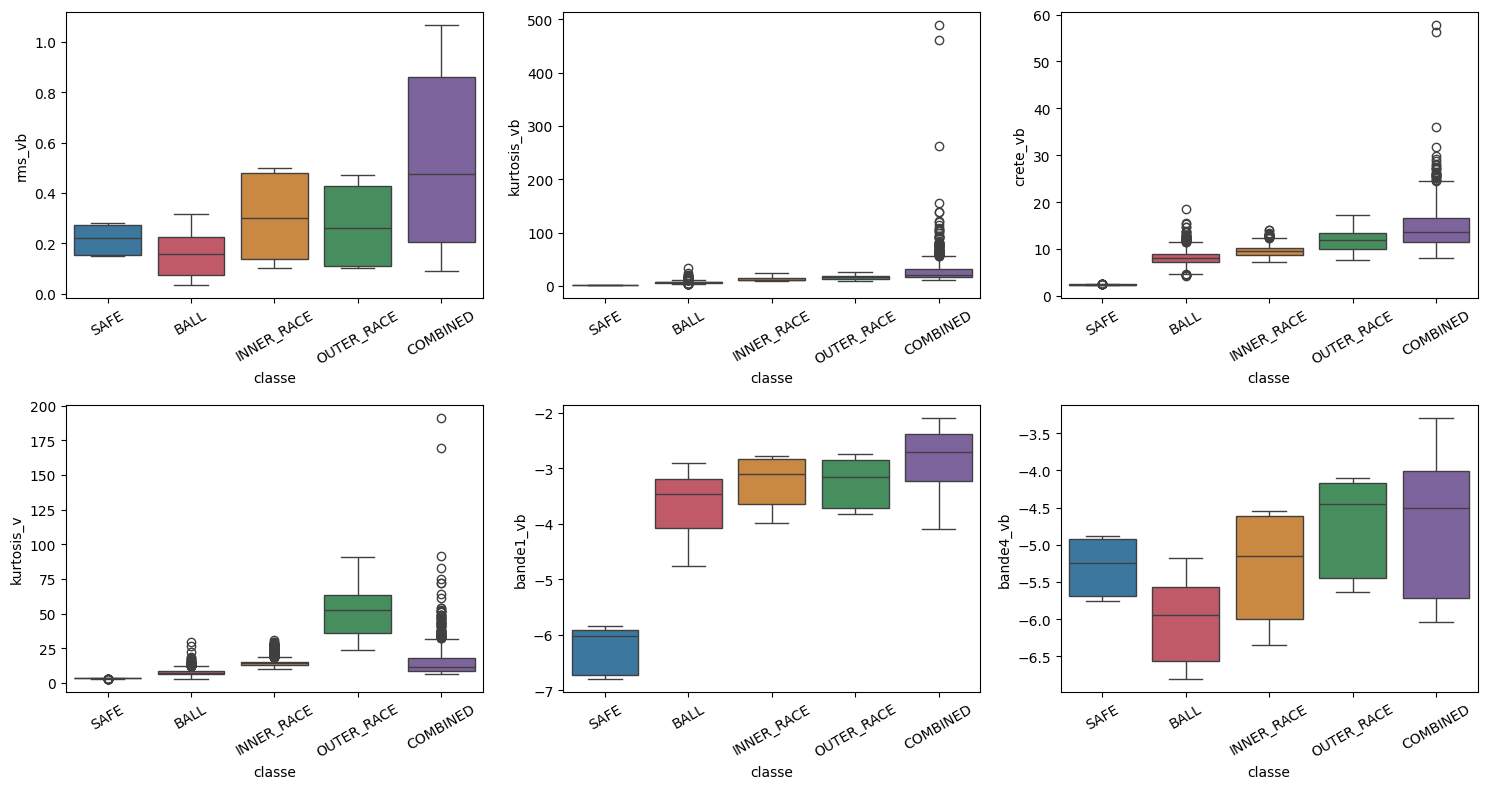

In [17]:
a_tracer = ["rms_vb", "kurtosis_vb", "crete_vb", "kurtosis_v", "bande1_vb", "bande4_vb"]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, col in zip(ax.flat, a_tracer):
    sns.boxplot(data=train, x="classe", y=col, order=CLASSES, palette=COULEURS, hue="classe", ax=a)
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### 4.2 Effet de la vitesse
La vitesse est un **facteur de confusion** potentiel : si elle modifie fortement les descripteurs, le clustering risque de regrouper par vitesse plutôt que par défaut.

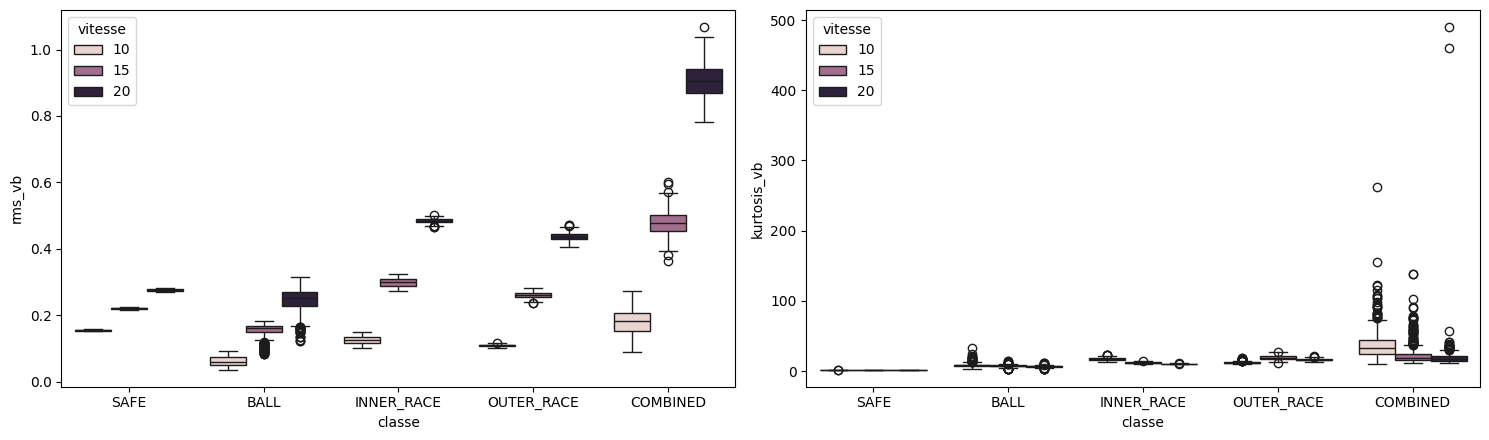

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, col in zip(ax, ["rms_vb", "kurtosis_vb"]):
    sns.boxplot(data=train, x="classe", y=col, hue="vitesse", order=CLASSES, ax=a)
plt.tight_layout(); plt.show()

### 4.3 Corrélations entre descripteurs
Des descripteurs très corrélés portent la même information. Ce n'est pas bloquant pour un autoencodeur (il apprend justement à compresser cette redondance), mais c'est utile à commenter.

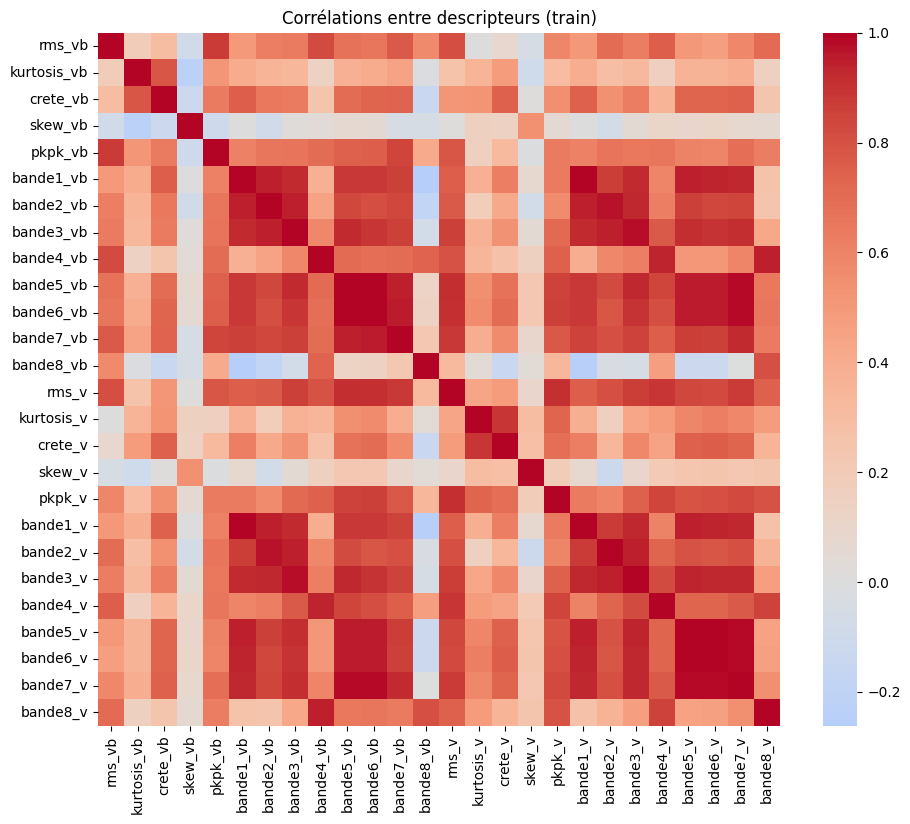

In [19]:
plt.figure(figsize=(11, 9))
sns.heatmap(train[FEATURES].corr(), cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.title("Corrélations entre descripteurs (train)"); plt.show()

### 4.4 Vue d'ensemble en 2D (ACP)
L'**ACP** (analyse en composantes principales) projette les 26 descripteurs sur les 2 directions de plus grande variance. On colore les points par classe, puis par vitesse : on voit si les classes forment des groupes naturels, et si la vitesse structure les données.

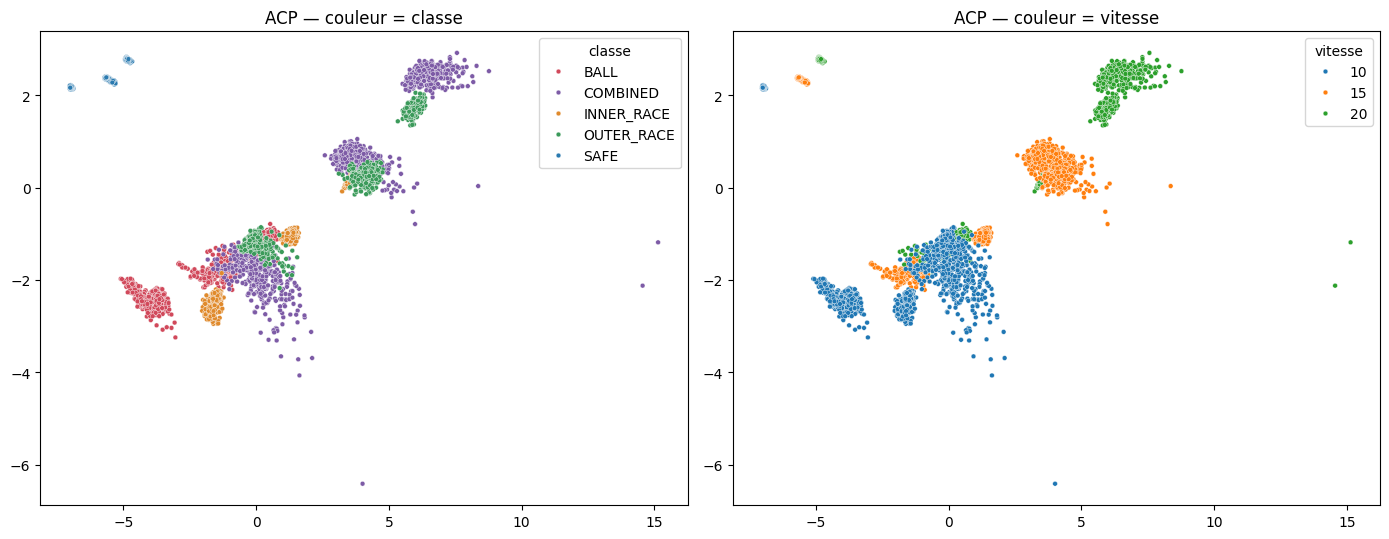

In [20]:
X_vis = StandardScaler().fit_transform(train[FEATURES])
Z_vis = PCA(n_components=2, random_state=SEED).fit_transform(X_vis)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=Z_vis[:, 0], y=Z_vis[:, 1], hue=train.classe, palette=COULEURS, s=12, ax=ax[0])
sns.scatterplot(x=Z_vis[:, 0], y=Z_vis[:, 1], hue=train.vitesse.astype(str), s=12, ax=ax[1])
ax[0].set_title("ACP — couleur = classe"); ax[1].set_title("ACP — couleur = vitesse")
plt.tight_layout(); plt.show()

---
## 5. Les autoencodeurs : principe

### 5.1 Idée
Un **autoencodeur** (AE) est un réseau de neurones entraîné à **reproduire son entrée** : on lui donne $x$, il doit ressortir $\hat{x} \approx x$.

```
  entrée x          encodeur          code z          décodeur          sortie x̂
 (26 valeurs)  →  26 → 16 → 6   →   (6 valeurs)   →   6 → 16 → 26   →  (26 valeurs)
                                    « goulot »
```

L'intérêt vient du **goulot d'étranglement** : la couche du milieu est plus petite que l'entrée. Pour reconstruire $x$ à partir de seulement 6 nombres, le réseau est obligé d'apprendre une **représentation compressée** qui garde l'essentiel de l'information et rejette le bruit.

- **Encodeur** $z = f(x)$ : compresse l'entrée vers l'espace latent.
- **Décodeur** $\hat{x} = g(z)$ : reconstruit l'entrée à partir du code.
- **Espace latent** : l'ensemble des codes $z$.

### 5.2 Apprentissage
On minimise l'**erreur de reconstruction**, ici l'erreur quadratique moyenne (MSE) :

$$\mathcal{L}(x, \hat{x}) = \frac{1}{d}\sum_{k=1}^{d} (x_k - \hat{x}_k)^2$$

par descente de gradient (rétropropagation), exactement comme un réseau de régression... sauf que **la cible est l'entrée elle-même**. C'est un apprentissage **non supervisé** : aucune étiquette n'est utilisée.

> Avec scikit-learn, c'est littéralement `MLPRegressor(...).fit(X, X)` : on demande au réseau de prédire X à partir de X.

### 5.3 Deux usages pour notre projet

| Usage | Ce qu'on exploite | Idée |
|---|---|---|
| **Détection d'anomalie** | l'erreur de reconstruction | entraîné **seulement sur des signaux sains**, l'AE reconstruit bien ce qui ressemble à du sain et **mal ce qui est anormal** → erreur élevée = anomalie |
| **Clustering** | le code latent $z$ | $z$ est une représentation compacte et débruitée ; des signaux similaires ont des codes proches → on applique k-means sur $z$ |

### 5.4 Lien avec l'ACP
Un AE **linéaire** (sans fonction d'activation) avec une perte MSE apprend le même sous-espace que l'**ACP**. Les fonctions d'activation non linéaires (ici `tanh`) permettent à l'AE de capturer des structures **non linéaires**. C'est pourquoi l'ACP est une bonne **baseline** : si l'AE ne fait pas mieux, sa complexité n'est pas justifiée.

### 5.5 Variantes (pour la partie théorique du rapport et les améliorations)
- **AE convolutif 1D** : traite directement le signal brut avec des filtres glissants ;
- **AE débruitant** : on bruite l'entrée et on demande de reconstruire la version propre ;
- **AE variationnel (VAE)** : l'espace latent est probabiliste, utile pour générer et pour un score d'anomalie probabiliste ;
- **Deep Embedded Clustering (DEC)** : entraîne conjointement l'AE et le clustering.

### 5.6 Outils communs
Trois petites fonctions réutilisées dans toute la suite :
- `creer_ae` : construit l'autoencodeur ;
- `erreur_reconstruction` : erreur MSE **par signal** (une valeur par ligne) ;
- `encoder` : calcule le code latent $z$ en appliquant seulement la moitié « encodeur » du réseau.

In [22]:
def creer_ae(couches=(16, 6, 16)):
    # couches = tailles des couches cachées ; celle du milieu est le goulot (espace latent)
    return MLPRegressor(hidden_layer_sizes=couches,
                        activation="tanh",
                        learning_rate_init=1e-3,
                        max_iter=1000,
                        early_stopping=True,        # garde 10 % du train pour arrêter avant le sur-apprentissage
                        n_iter_no_change=30,
                        random_state=SEED)

def erreur_reconstruction(ae, X):
    return np.mean((X - ae.predict(X)) ** 2, axis=1)

def encoder(ae, X):
    # ae.coefs_[k] et ae.intercepts_[k] = poids et biais de la couche k.
    # L'encodeur = les couches jusqu'au goulot (inclus).
    n_couches_encodeur = len(ae.hidden_layer_sizes) // 2 + 1
    h = X
    for W, b in zip(ae.coefs_[:n_couches_encodeur], ae.intercepts_[:n_couches_encodeur]):
        h = np.tanh(h @ W + b)
    return h

---
## 6. Détection d'anomalie

### 6.1 Stratégie

1. **Entraîner** sur les signaux **SAFE du train uniquement** : le modèle apprend ce qu'est un fonctionnement normal. (On n'a pas besoin d'exemples de défauts pour entraîner : c'est l'avantage de l'approche, car en industrie les défauts sont rares.)
2. **Score d'anomalie** = erreur de reconstruction.
3. **Seuil** : on le fixe sur les signaux **SAFE de validation**, au 99ᵉ percentile de leurs erreurs. Interprétation : on accepte environ 1 % de fausses alarmes sur des roulements sains.
4. **Évaluation sur le test** (toutes classes) : un signal est déclaré « anomalie » si son erreur dépasse le seuil.

**Métriques**
- **AUROC** : probabilité qu'un signal défectueux tiré au hasard ait un score plus élevé qu'un signal sain tiré au hasard. Ne dépend pas du seuil. 0,5 = hasard, 1 = parfait.
- **Matrice de confusion**, **précision** (parmi les alarmes, combien sont de vrais défauts), **rappel** (parmi les défauts, combien sont détectés).

**Modèles comparés**
- *Baseline 1* — **Isolation Forest** : isole les points atypiques par des découpages aléatoires ;
- *Baseline 2* — **ACP** : même principe que l'AE (erreur de reconstruction) mais linéaire ;
- **Autoencodeur**.

### 6.2 Préparation des données
La **standardisation** (moyenne 0, écart-type 1 pour chaque colonne) est indispensable pour un réseau de neurones : sans elle, les colonnes de grande amplitude domineraient l'erreur. Le `StandardScaler` est ajusté (**fit**) sur le **train SAFE** uniquement, puis appliqué (**transform**) à tout le reste.

In [23]:
scaler = StandardScaler().fit(bd.loc[(bd.split == "train") & (bd.classe == "SAFE"), FEATURES])
X = scaler.transform(bd[FEATURES])
y = (bd.classe != "SAFE").astype(int).to_numpy()     # 1 = défaut, 0 = sain (servira UNIQUEMENT à évaluer)

m_train_safe = ((bd.split == "train") & (bd.classe == "SAFE")).to_numpy()
m_val_safe   = ((bd.split == "val")   & (bd.classe == "SAFE")).to_numpy()
m_test       = (bd.split == "test").to_numpy()

print("entraînement :", m_train_safe.sum(), "signaux SAFE")
print("seuil       :", m_val_safe.sum(), "signaux SAFE")
print("test        :", m_test.sum(), "signaux (toutes classes)")

entraînement : 1197 signaux SAFE
seuil       : 257 signaux SAFE
test        : 1265 signaux (toutes classes)


### 6.3 Entraînement de l'autoencodeur
La **courbe de perte** doit décroître puis se stabiliser. Si elle remonte sur la validation interne, le modèle sur-apprend (`early_stopping` l'arrête alors automatiquement).

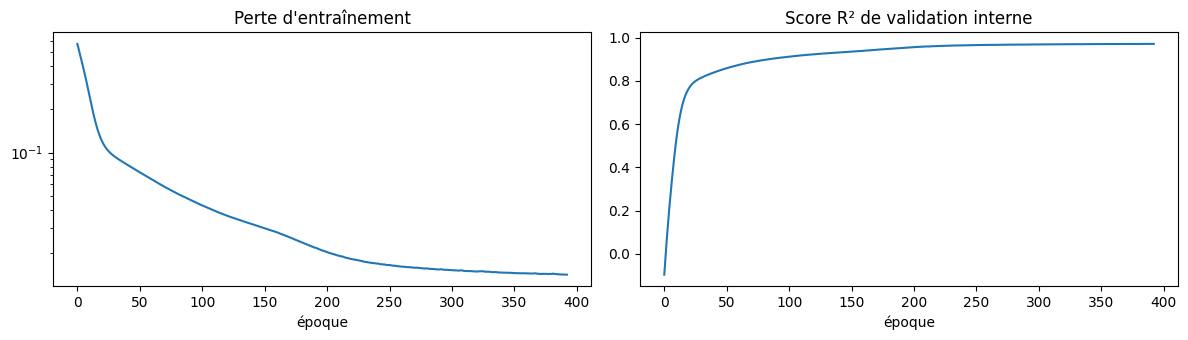

393 époques


In [24]:
ae = creer_ae((16, 6, 16))
ae.fit(X[m_train_safe], X[m_train_safe])          # entrée = cible : l'AE apprend à reproduire les signaux sains

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(ae.loss_curve_); ax[0].set(title="Perte d'entraînement", xlabel="époque", yscale="log")
ax[1].plot(ae.validation_scores_); ax[1].set(title="Score R² de validation interne", xlabel="époque")
plt.tight_layout(); plt.show()
print(f"{ae.n_iter_} époques")

### 6.4 Scores, seuil et comparaison avec les baselines
Pour chaque modèle, on calcule un **score d'anomalie** (plus il est grand, plus le signal est suspect).

In [25]:
# Baseline 1 : Isolation Forest (score_samples est grand pour les points normaux -> on prend l'opposé)
iso = IsolationForest(n_estimators=300, random_state=SEED).fit(X[m_train_safe])
score_iso = -iso.score_samples(X)

# Baseline 2 : ACP avec la même taille de "goulot" que l'AE (6 composantes)
pca = PCA(n_components=6, random_state=SEED).fit(X[m_train_safe])
score_pca = np.mean((X - pca.inverse_transform(pca.transform(X))) ** 2, axis=1)

# Autoencodeur
score_ae = erreur_reconstruction(ae, X)

scores = {"Isolation Forest": score_iso, "ACP": score_pca, "Autoencodeur": score_ae}

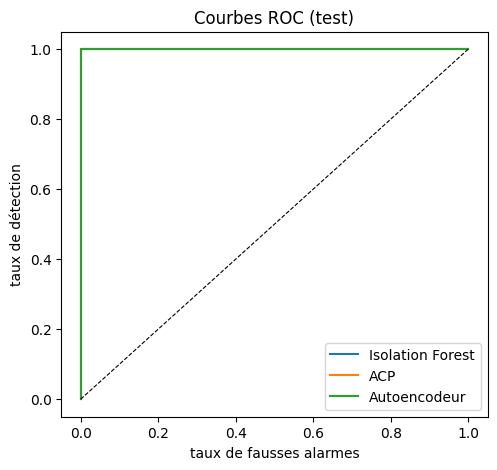

,AUROC,rappel (défauts détectés),taux de fausses alarmes,précision
modèle,,,,
Isolation Forest,1.0,1.0,0.023,0.994
ACP,1.0,1.0,0.012,0.997
Autoencodeur,1.0,1.0,0.012,0.997


In [26]:
resultats = []
plt.figure(figsize=(5.5, 5))
for nom, s in scores.items():
    seuil = np.percentile(s[m_val_safe], 99)              # seuil fixé SANS regarder le test
    pred = (s[m_test] > seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y[m_test], pred).ravel()
    resultats.append({"modèle": nom,
                      "AUROC": roc_auc_score(y[m_test], s[m_test]),
                      "rappel (défauts détectés)": tp / (tp + fn),
                      "taux de fausses alarmes": fp / (fp + tn),
                      "précision": tp / max(tp + fp, 1)})
    fpr, tpr, _ = roc_curve(y[m_test], s[m_test])
    plt.plot(fpr, tpr, label=nom)
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("taux de fausses alarmes"); plt.ylabel("taux de détection"); plt.title("Courbes ROC (test)")
plt.legend(); plt.show()

pd.DataFrame(resultats).set_index("modèle").round(3)

### 6.5 Analyse des résultats de l'autoencodeur

**Distribution des erreurs par classe** : idéalement, SAFE reste sous le seuil et tous les défauts au-dessus.

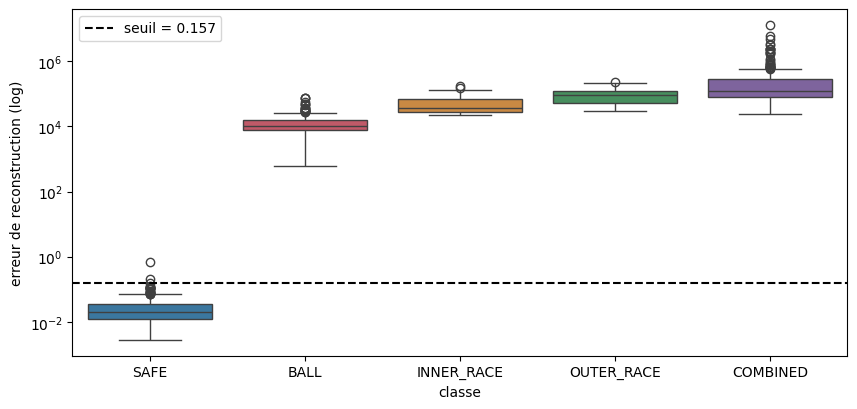

In [27]:
seuil_ae = np.percentile(score_ae[m_val_safe], 99)
test = bd[m_test].assign(score=score_ae[m_test], alarme=score_ae[m_test] > seuil_ae)

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=test, x="classe", y="score", order=CLASSES, palette=COULEURS, hue="classe")
plt.axhline(seuil_ae, color="k", ls="--", label=f"seuil = {seuil_ae:.3f}")
plt.yscale("log"); plt.ylabel("erreur de reconstruction (log)"); plt.legend(); plt.show()

**Taux d'alarme par classe et par vitesse** : pour SAFE c'est le taux de fausses alarmes (doit être faible), pour les défauts c'est le taux de détection (doit être proche de 1). On vérifie que la performance ne dépend pas de la vitesse.

In [28]:
test.pivot_table(index="classe", columns="vitesse", values="alarme", aggfunc="mean").loc[CLASSES].round(3)

vitesse,10,15,20
classe,,,
SAFE,0.0,0.03,0.0
BALL,1.0,1.00,1.0
INNER_RACE,1.0,1.00,1.0
OUTER_RACE,1.0,1.00,1.0
COMBINED,1.0,1.00,1.0


### 6.6 Interprétabilité : quels descripteurs signalent l'anomalie ?

L'erreur de reconstruction est une **somme sur les descripteurs** : on peut donc la **décomposer** et regarder quels descripteurs l'AE reconstruit mal pour chaque type de défaut. C'est une méthode d'interprétabilité naturelle pour un autoencodeur.

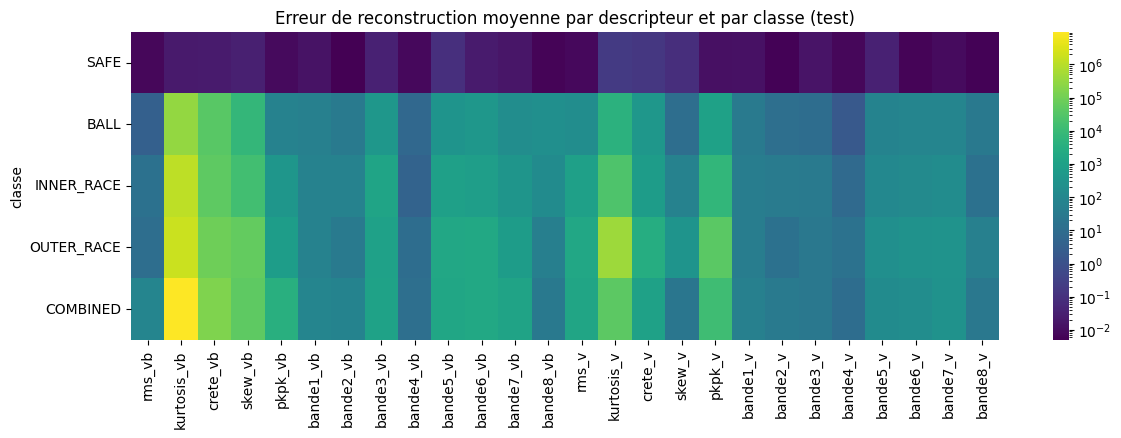

In [29]:
erreur_par_feature = pd.DataFrame((X[m_test] - ae.predict(X[m_test])) ** 2, columns=FEATURES)
erreur_par_feature["classe"] = bd.classe[m_test].to_numpy()

plt.figure(figsize=(14, 4))
sns.heatmap(erreur_par_feature.groupby("classe")[FEATURES].mean().loc[CLASSES],
            cmap="viridis", xticklabels=True, norm=LogNorm())
plt.title("Erreur de reconstruction moyenne par descripteur et par classe (test)"); plt.show()

**Analyse des erreurs** : quels signaux sont mal classés ? (fausses alarmes sur SAFE, défauts non détectés). Regardez leur classe, leur vitesse, et réécoutez/retracez ces signaux pour comprendre.

In [30]:
erreurs = test[(test.classe == "SAFE") == test.alarme]          # SAFE en alarme, ou défaut sans alarme
print(f"{len(erreurs)} signaux mal classés sur {len(test)}")
erreurs[["classe", "vitesse", "fichier", "score"]].sort_values("score")

3 signaux mal classés sur 1265


,classe,vitesse,fichier,score
7819,SAFE,15,safe_1489_639.xlsx,0.162383
7758,SAFE,15,safe_1489_584.xlsx,0.205088
7756,SAFE,15,safe_1489_582.xlsx,0.703473


### 6.7 Pour aller plus loin : même méthode sur le spectre complet

On remplace les 26 descripteurs par le **spectre complet** (512 valeurs : 256 fréquences × 2 capteurs). Le modèle a plus d'information à exploiter, sans qu'on ait choisi les descripteurs à la main. **Le code est identique** : seules l'entrée et la taille des couches changent.

In [31]:
scaler_spec = StandardScaler().fit(SPECTRES[m_train_safe])
X_spec = scaler_spec.transform(SPECTRES)

ae_spec = creer_ae((128, 16, 128))
ae_spec.fit(X_spec[m_train_safe], X_spec[m_train_safe])

score_spec = erreur_reconstruction(ae_spec, X_spec)
seuil_spec = np.percentile(score_spec[m_val_safe], 99)
pred = score_spec[m_test] > seuil_spec
print(f"AUROC = {roc_auc_score(y[m_test], score_spec[m_test]):.3f}")
print(classification_report(y[m_test], pred, target_names=["SAFE", "défaut"]))

AUROC = 1.000
              precision    recall  f1-score   support

        SAFE       1.00      1.00      1.00       256
      défaut       1.00      1.00      1.00      1009

    accuracy                           1.00      1265
   macro avg       1.00      1.00      1.00      1265
weighted avg       1.00      1.00      1.00      1265



---
## 7. Clustering

### 7.1 Stratégie

Objectif : retrouver **les 5 états du roulement sans utiliser les étiquettes**, puis vérifier a posteriori si les groupes trouvés correspondent aux vraies classes.

1. **Entraîner un nouvel autoencodeur sur tout le train** (toutes classes, sans étiquette). L'AE de la partie 6 ne convient pas : il n'a vu que du SAFE, son espace latent n'a donc pas appris à représenter les différences entre défauts.
2. **Encoder** chaque signal → code latent $z$ (6 valeurs).
3. **Choisir le nombre de groupes** $k$ avec le **coefficient de silhouette** (de -1 à 1 : élevé = groupes compacts et bien séparés), sans regarder les étiquettes.
4. **k-means** sur les codes latents du train, puis affectation des signaux de test à un groupe.
5. **Évaluation** sur le test, avec les étiquettes (uniquement pour juger) :
   - **ARI** (*Adjusted Rand Index*) : accord entre clusters et vraies classes, 0 = hasard, 1 = parfait ;
   - **NMI** (*Normalized Mutual Information*) : information partagée, de 0 à 1 ;
   - **table de contingence** classe × cluster.
6. **Vérification du facteur de confusion** : on calcule aussi l'ARI entre clusters et **vitesse**. S'il est élevé, les groupes reflètent la vitesse plutôt que le défaut.

**Baseline** : k-means directement sur les 26 descripteurs standardisés.

### 7.2 Préparation et entraînement
Cette fois le `StandardScaler` est ajusté sur **tout le train**.

In [32]:
m_train = (bd.split == "train").to_numpy()

scaler_clu = StandardScaler().fit(bd.loc[m_train, FEATURES])
X_clu = scaler_clu.transform(bd[FEATURES])

ae_clu = creer_ae((16, 6, 16))
ae_clu.fit(X_clu[m_train], X_clu[m_train])
print(f"{ae_clu.n_iter_} époques")

Z = encoder(ae_clu, X_clu)          # codes latents de TOUS les signaux, forme (N, 6)
Z.shape

386 époques


(8431, 6)

### 7.3 Choix du nombre de clusters
On sait qu'il y a 5 classes, mais on vérifie ce que suggèrent les données elles-mêmes : c'est une information intéressante (par ex. si COMBINED se confond avec un autre défaut, la silhouette peut préférer k = 4).

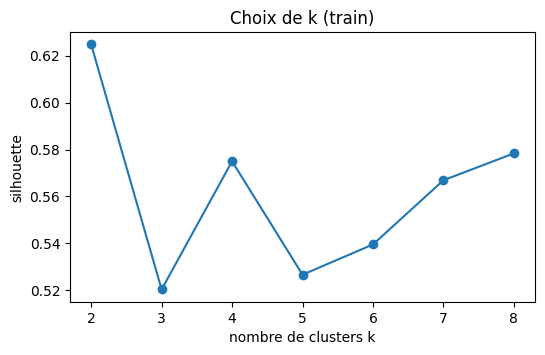

In [33]:
ks = range(2, 9)
sil = [silhouette_score(Z[m_train], KMeans(k, n_init=10, random_state=SEED).fit_predict(Z[m_train])) for k in ks]

plt.figure(figsize=(6, 3.5))
plt.plot(list(ks), sil, "o-"); plt.xlabel("nombre de clusters k"); plt.ylabel("silhouette")
plt.title("Choix de k (train)"); plt.show()

### 7.4 k-means sur l'espace latent vs baseline

In [34]:
K = 5   # à ajuster selon la courbe de silhouette

def evaluer_clustering(nom, donnees):
    km = KMeans(K, n_init=10, random_state=SEED).fit(donnees[m_train])
    clusters = km.predict(donnees[m_test])
    return clusters, {"méthode": nom,
                      "silhouette": silhouette_score(donnees[m_test], clusters),
                      "ARI vs classe": adjusted_rand_score(bd.classe[m_test], clusters),
                      "NMI vs classe": normalized_mutual_info_score(bd.classe[m_test], clusters),
                      "ARI vs vitesse": adjusted_rand_score(bd.vitesse[m_test], clusters)}

clusters_base, res_base = evaluer_clustering("k-means sur descripteurs (baseline)", X_clu)
clusters_ae, res_ae = evaluer_clustering("k-means sur espace latent AE", Z)

pd.DataFrame([res_base, res_ae]).set_index("méthode").round(3)

,silhouette,ARI vs classe,NMI vs classe,ARI vs vitesse
méthode,,,,
k-means sur descripteurs (baseline),0.492,0.525,0.694,0.104
k-means sur espace latent AE,0.530,0.510,0.666,0.226


**Table de contingence** (test) : chaque ligne est une vraie classe, chaque colonne un cluster. Un clustering parfait aurait une seule case non nulle par ligne et par colonne.

In [35]:
pd.crosstab(bd.classe[m_test], clusters_ae, rownames=["classe"], colnames=["cluster"]).loc[CLASSES]

cluster,0,1,2,3,4
classe,,,,,
SAFE,0,256,0,0,0
BALL,0,0,187,0,68
INNER_RACE,0,0,84,0,182
OUTER_RACE,0,0,78,163,0
COMBINED,165,0,82,0,0


### 7.5 Visualisation de l'espace latent
L'espace latent a 6 dimensions : pour le voir, on le projette en 2D avec **t-SNE**, une méthode qui préserve les voisinages (deux points proches en 6D restent proches en 2D). Attention : les distances entre groupes éloignés et la taille des groupes sur un graphe t-SNE ne sont pas interprétables.

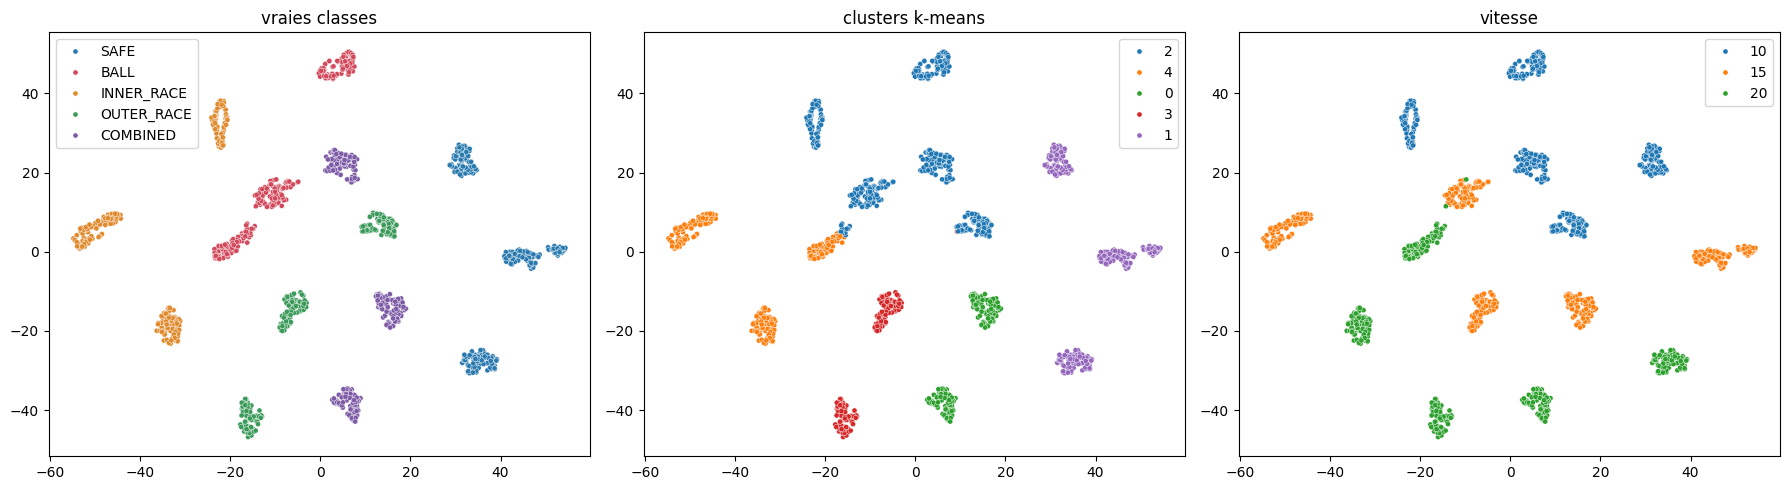

In [36]:
Z_2d = TSNE(n_components=2, random_state=SEED, perplexity=min(30, m_test.sum() - 1)).fit_transform(Z[m_test])

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(x=Z_2d[:, 0], y=Z_2d[:, 1], hue=bd.classe[m_test].to_numpy(), hue_order=CLASSES, palette=COULEURS, s=14, ax=ax[0])
sns.scatterplot(x=Z_2d[:, 0], y=Z_2d[:, 1], hue=clusters_ae.astype(str), palette="tab10", s=14, ax=ax[1])
sns.scatterplot(x=Z_2d[:, 0], y=Z_2d[:, 1], hue=bd.vitesse[m_test].astype(str).to_numpy(), s=14, ax=ax[2])
ax[0].set_title("vraies classes"); ax[1].set_title("clusters k-means"); ax[2].set_title("vitesse")
plt.tight_layout(); plt.show()

---
## 8. Sauvegarde, bilan et pistes d'amélioration

### 8.1 Sauvegarde des modèles
Pour l'application de démonstration (Streamlit), on sauvegarde tout ce qu'il faut pour analyser un nouveau fichier : la fonction `extraire` (à recopier dans l'app), les scalers, les modèles et le seuil.

In [ ]:
import joblib
joblib.dump({"features": FEATURES,
             "scaler_detection": scaler, "ae_detection": ae, "seuil": seuil_ae,
             "scaler_clustering": scaler_clu, "ae_clustering": ae_clu,
             "kmeans": KMeans(K, n_init=10, random_state=SEED).fit(Z[m_train])},
            "modeles_v1.joblib")

### 8.2 Bilan (à compléter avec vos résultats)
- Détection : quel modèle est le meilleur ? L'AE apporte-t-il un gain par rapport à l'ACP et à l'Isolation Forest ?
- Quels descripteurs trahissent chaque défaut (partie 6.6) ? Est-ce cohérent avec la physique (kurtosis élevée = chocs) ?
- Clustering : quelles classes sont bien séparées ? Lesquelles se confondent ? La vitesse influence-t-elle les groupes ?

### 8.3 Pistes pour une base de données v2 et des modèles plus avancés
1. **Descripteurs d'enveloppe** : énergie du spectre d'enveloppe aux fréquences caractéristiques des défauts (BPFO, BPFI, BSF), qui dépendent de la géométrie du roulement et de la vitesse.
2. **Normalisation par vitesse** pour réduire le facteur de confusion.
3. **Autoencodeur convolutif 1D** (PyTorch) sur le signal brut ou le spectre : le modèle apprend lui-même ses descripteurs.
4. **Robustesse** : entraîner sur les vitesses 10 et 20, tester sur 15.
5. **VAE** ou **DEC** pour un espace latent mieux structuré pour le clustering.